Reflection and Blogpost Writing¶

Setup

In [1]:
from getpass import getpass

def get_openai_api_key():
    return getpass("Enter your OpenAI API key: ")

OPENAI_API_KEY = get_openai_api_key()

llm_config = {
    "model": "gpt-6-luna",
    "api_key": OPENAI_API_KEY
}

print("OpenAI configuration created successfully!")

Enter your OpenAI API key:  ········


OpenAI configuration created successfully!


The Task

In [2]:
task = '''
        Write a concise but engaging blogpost about
      Hope AI . Make sure the blogpost is
       within 100 words.
       '''

Create a writer agent

In [3]:
import autogen

writer = autogen.AssistantAgent(
    name="Writer",
    system_message="You are a writer. You write engaging and concise " 
        "blogpost (with title) on given topics. You must polish your "
        "writing based on the feedback you receive and give a refined "
        "version. Only return your final work without additional comments.",
    llm_config=llm_config,
)

C:\Anaconda3\envs\agenticAI\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)
C:\Anaconda3\envs\agenticAI\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.cloud.resourcemanager_v3 once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.cloud.resourcemanager_v3 past that date.
  warnings.warn(message, FutureWarning)


In [4]:
reply = writer.generate_reply(messages=[{"content": task,"role": "user"}])
print(reply)

[autogen.oai.client: 11-19 13:57:06] {573} WARNING - Model gpt-6-luna is not found. The cost will be 0. In your config_list, add field {"price" : [prompt_price_per_1k, completion_token_price_per_1k]} for customized pricing.
# Hope AI: A Brighter Future, Built Together

AI can feel like a force rushing ahead of us. But it can also help us imagine—and build—a better future: detecting illness earlier, making learning more personal, and giving people more time for meaningful work.

Hope in AI doesn’t mean believing every promise. It means pairing ambition with responsibility: protecting privacy, reducing bias, and keeping people in control.

The future isn’t something AI decides for us. It’s something we shape together, one thoughtful choice at a time.


Adding reflection¶:
Create a critic agent to reflect on the work of the writer agent.

In [5]:
critic = autogen.AssistantAgent(
    name="Critic",
    is_termination_msg=lambda x: x.get("content", "").find("TERMINATE") >= 0,
    llm_config=llm_config,
    system_message="You are a critic. You review the work of "
                "the writer and provide constructive "
                "feedback to help improve the quality of the content.",
)

In [6]:
res = critic.initiate_chat(
    recipient=writer,
    message=task,
    max_turns=2,
    summary_method="last_msg"
)

Critic (to Writer):


        Write a concise but engaging blogpost about
      Hope AI . Make sure the blogpost is
       within 100 words.
       

--------------------------------------------------------------------------------
[autogen.oai.client: 11-19 13:57:39] {573} WARNING - Model gpt-6-luna is not found. The cost will be 0. In your config_list, add field {"price" : [prompt_price_per_1k, completion_token_price_per_1k]} for customized pricing.
Writer (to Critic):

# Hope AI: A Brighter Future, Built Together

Artificial intelligence can feel like a force we’re racing to catch. Hope AI offers a better way to think about it: not as a replacement for human judgment, but as a tool that helps people learn, create, and solve problems.

The real promise isn’t that machines will do everything. It’s that, used thoughtfully, they can give us more time and reach—and help turn ambitious ideas into practical progress.

Hope isn’t automatic. We build it through the choices we make with AI.

-

Nested chat

In [8]:
SEO_reviewer = autogen.AssistantAgent(
    name="SEO_Reviewer",
    llm_config=llm_config,
    system_message="You are an SEO reviewer, known for "
        "your ability to optimize content for search engines, "
        "ensuring that it ranks well and attracts organic traffic. " 
        "Make sure your suggestion is concise (within 3 bullet points), "
        "concrete and to the point. "
        "Begin the review by stating your role.",
)


In [9]:
legal_reviewer = autogen.AssistantAgent(
    name="Legal_Reviewer",
    llm_config=llm_config,
    system_message="You are a legal reviewer, known for "
        "your ability to ensure that content is legally compliant "
        "and free from any potential legal issues. "
        "Make sure your suggestion is concise (within 3 bullet points), "
        "concrete and to the point. "
        "Begin the review by stating your role.",
)

In [10]:
ethics_reviewer = autogen.AssistantAgent(
    name="Ethics_Reviewer",
    llm_config=llm_config,
    system_message="You are an ethics reviewer, known for "
        "your ability to ensure that content is ethically sound "
        "and free from any potential ethical issues. " 
        "Make sure your suggestion is concise (within 3 bullet points), "
        "concrete and to the point. "
        "Begin the review by stating your role. ",
)

In [11]:
meta_reviewer = autogen.AssistantAgent(
    name="Meta_Reviewer",
    llm_config=llm_config,
    system_message="You are a meta reviewer, you aggragate and review "
    "the work of other reviewers and give a final suggestion on the content.",
)

Orchestrate the nested chats to solve the task

In [12]:
def reflection_message(recipient, messages, sender, config):
    return f'''Review the following content. 
            \n\n {recipient.chat_messages_for_summary(sender)[-1]['content']}'''

review_chats = [
    {
     "recipient": SEO_reviewer, 
     "message": reflection_message, 
     "summary_method": "reflection_with_llm",
     "summary_args": {"summary_prompt" : 
        "Return review into as JSON object only:"
        "{'Reviewer': '', 'Review': ''}. Here Reviewer should be your role",},
     "max_turns": 1},
    {
    "recipient": legal_reviewer, "message": reflection_message, 
     "summary_method": "reflection_with_llm",
     "summary_args": {"summary_prompt" : 
        "Return review into as JSON object only:"
        "{'Reviewer': '', 'Review': ''}.",},
     "max_turns": 1},
    {"recipient": ethics_reviewer, "message": reflection_message, 
     "summary_method": "reflection_with_llm",
     "summary_args": {"summary_prompt" : 
        "Return review into as JSON object only:"
        "{'reviewer': '', 'review': ''}",},
     "max_turns": 1},
     {"recipient": meta_reviewer, 
      "message": "Aggregrate feedback from all reviewers and give final suggestions on the writing.", 
     "max_turns": 1},
]

In [13]:
critic.register_nested_chats(
    review_chats,
    trigger=writer, #final agent
)

In [14]:
res = critic.initiate_chat(
    recipient=writer,
    message=task,
    max_turns=2,
    summary_method="last_msg"
)

Critic (to Writer):


        Write a concise but engaging blogpost about
      Hope AI . Make sure the blogpost is
       within 100 words.
       

--------------------------------------------------------------------------------
Writer (to Critic):

# Hope AI: A Brighter Future, Built Together

Artificial intelligence can feel like a force we’re racing to catch. Hope AI offers a better way to think about it: not as a replacement for human judgment, but as a tool that helps people learn, create, and solve problems.

The real promise isn’t that machines will do everything. It’s that, used thoughtfully, they can give us more time and reach—and help turn ambitious ideas into practical progress.

Hope isn’t automatic. We build it through the choices we make with AI.

--------------------------------------------------------------------------------

********************************************************************************
Starting a new chat....

*************************************

In [15]:
print(res.summary)

# Hope AI: Putting Human Judgment at the Center

Hope AI is an initiative exploring how artificial intelligence can support people—not replace their judgment. For example, a teacher might use an AI tool to draft reading activities, then adapt them to suit each student.

That could save time, but results aren’t guaranteed. AI can make mistakes or reflect bias, so people need to review its suggestions and consider who may be left out.

The promise of Hope AI depends on how thoughtfully it’s built and used. Learn more, ask questions, and help shape AI that serves people well.


In [16]:
print(res.cost)

{'usage_including_cached_inference': {'total_cost': 0, 'gpt-6-luna': {'cost': 0, 'prompt_tokens': 1190, 'completion_tokens': 1340, 'total_tokens': 2530}}, 'usage_excluding_cached_inference': {'total_cost': 0, 'gpt-6-luna': {'cost': 0, 'prompt_tokens': 1102, 'completion_tokens': 1183, 'total_tokens': 2285}}}


In [17]:
print(res.chat_history)

[{'content': '\n        Write a concise but engaging blogpost about\n      Hope AI . Make sure the blogpost is\n       within 100 words.\n       ', 'role': 'assistant', 'name': 'Critic'}, {'content': '# Hope AI: A Brighter Future, Built Together\n\nArtificial intelligence can feel like a force we’re racing to catch. Hope AI offers a better way to think about it: not as a replacement for human judgment, but as a tool that helps people learn, create, and solve problems.\n\nThe real promise isn’t that machines will do everything. It’s that, used thoughtfully, they can give us more time and reach—and help turn ambitious ideas into practical progress.\n\nHope isn’t automatic. We build it through the choices we make with AI.', 'role': 'user', 'name': 'Writer'}, {'content': '### Overall assessment\nThe writing has a warm, optimistic, human-centered message: AI should support, not replace, human judgment. Reviewers agree that the main weakness is that the claims remain abstract and are not yet

In [18]:
!pip install matplotlib

  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 MB 7.1 MB/s eta 0:00:02
   ----- ---------------------------------- 1.3/9.3 MB 6.1 MB/s eta 0:00:02
   ----------- ---------------------------- 2.6/9.3 MB 4.6 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.3 MB 4.4 MB/s eta 0:00:02
   ------------------- -------------------- 4.5/9.3 MB 4.2 MB/s eta 0:00:02
   ---------------------- ----------------- 5.2/9.3 MB 4.2 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.3 MB 4.1 MB/s eta 0:00:01
   ---------------------------- ----------- 6.6/9.3 MB 4.1 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 4.0 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 4.1 MB/s eta 0:00:01
   -----------------------------

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

Store Your Original Input

In [20]:
data = [
    {
        'content': 'Write a concise but engaging blogpost about Hope AI. Make sure the blogpost is within 100 words.',
        'role': 'assistant',
        'name': 'Critic'
    },
    {
        'content': '''# Hope AI: A Brighter Future, Built Together

Artificial intelligence can feel like a force we’re racing to catch. Hope AI offers a better way to think about it: not as a replacement for human judgment, but as a tool that helps people learn, create, and solve problems.

The real promise isn’t that machines will do everything. It’s that, used thoughtfully, they can give us more time and reach—and help turn ambitious ideas into practical progress.

Hope isn’t automatic. We build it through the choices we make with AI.''',
        'role': 'user',
        'name': 'Writer'
    },
    {
        'content': '''Overall assessment: The writing has a warm, optimistic, human-centered message. The main weakness is that claims remain abstract and need examples or evidence.''',
        'role': 'assistant',
        'name': 'Critic'
    },
    {
        'content': '''# Hope AI: Putting Human Judgment at the Center

Hope AI is an initiative exploring how artificial intelligence can support people—not replace their judgment. For example, a teacher might use an AI tool to draft reading activities, then adapt them to suit each student.

That could save time, but results aren’t guaranteed. AI can make mistakes or reflect bias, so people need to review its suggestions and consider who may be left out.

The promise of Hope AI depends on how thoughtfully it’s built and used. Learn more, ask questions, and help shape AI that serves people well.''',
        'role': 'user',
        'name': 'Writer'
    }
]

In [21]:
df = pd.DataFrame(data)

print(df)

                                             content       role    name
0  Write a concise but engaging blogpost about Ho...  assistant  Critic
1  # Hope AI: A Brighter Future, Built Together\n...       user  Writer
2  Overall assessment: The writing has a warm, op...  assistant  Critic
3  # Hope AI: Putting Human Judgment at the Cente...       user  Writer


Perform Statistical Analysis

In [22]:
df['word_count'] = df['content'].apply(
    lambda x: len(x.split())
)

df['character_count'] = df['content'].apply(
    lambda x: len(x)
)

df['line_count'] = df['content'].apply(
    lambda x: len(x.splitlines())
)

print("Total Messages:", len(df))

print("\nRole Distribution:")
print(df['role'].value_counts())

print("\nStatistical Summary:")
print(df[['word_count', 'character_count', 'line_count']].describe())

Total Messages: 4

Role Distribution:
role
assistant    2
user         2
Name: count, dtype: int64

Statistical Summary:
       word_count  character_count  line_count
count    4.000000         4.000000    4.000000
mean    56.750000       338.750000    4.000000
std     42.664388       246.422909    3.464102
min     17.000000        96.000000    1.000000
25%     21.500000       143.250000    1.000000
50%     56.000000       340.000000    4.000000
75%     91.250000       535.500000    7.000000
max     98.000000       579.000000    7.000000


Visualize Statistics
A. Word Count per Message

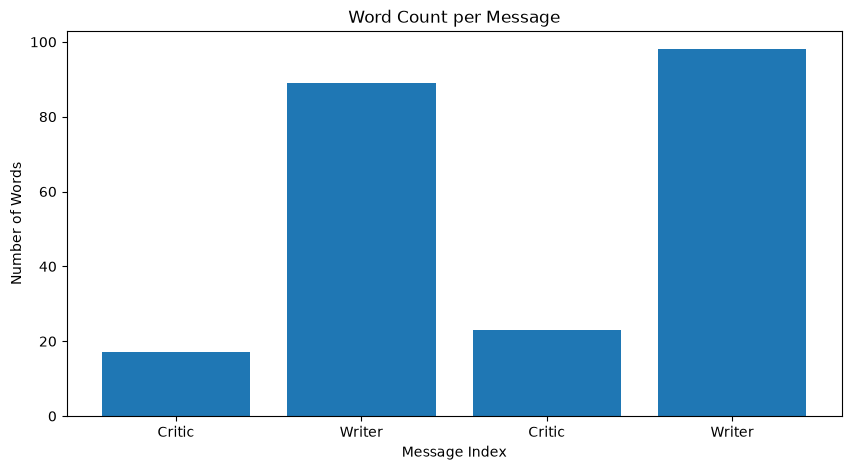

In [23]:
plt.figure(figsize=(10, 5))

plt.bar(df.index, df['word_count'])

plt.title('Word Count per Message')
plt.xlabel('Message Index')
plt.ylabel('Number of Words')

plt.xticks(df.index, df['name'])

plt.show()